# FraudScope — Partie 1 : Prétraitement et analyse exploratoire des données

**Cours :** INF5103 — Concepts statistiques pour la science des données

**Objectif :** Étudier un jeu de données de transactions bancaires afin de comprendre ses caractéristiques, vérifier sa qualité et préparer les données pour un futur modèle de détection des fraudes.

## Méthodologie

Le travail suit les étapes suivantes :

1. Chargement et exploration du jeu de données.
2. Vérification des valeurs manquantes, doublons et incohérences.
3. Analyse statistique des variables.
4. Visualisation des montants et comparaison des transactions.
5. Analyse du déséquilibre entre transactions normales et frauduleuses.
6. Séparation stratifiée entre entraînement et test.
7. Rééquilibrage de l'ensemble d'entraînement par suréchantillonnage aléatoire.
8. Vérification des résultats et préparation pour la modélisation.

**Jeu de données :** Credit Card Fraud Detection 2026 (Kaggle).

**Outils utilisés :** Python, Pandas, Matplotlib, Scikit-learn et Jupyter Notebook.

In [1]:
import pandas as pd

df = pd.read_csv("credit_card_fraud_2026.csv")

df.head()

,transaction_id,amount_usd,merchant_category,card_type,auth_method,channel,device_type,is_foreign_transaction,hours_since_last_txn,txn_count_last_24h,...,ip_country_mismatch,billing_shipping_mismatch,cvv_retry_count,velocity_score,time_of_day_hour,day_of_week,is_ai_generated_scam_attempt,merchant_risk_score,prior_disputes,is_fraud
0,1,42.86,Restaurants,Visa,OTP,Online,Android Phone,False,13.54,2,...,False,False,0,0.1,18,3,False,42.3,0,0
1,2,4.75,Online Retail,Mastercard,3D Secure,Online,Android Phone,False,0.71,2,...,False,False,0,25.8,12,4,False,28.3,0,0
2,3,77.18,Groceries,Mastercard,3D Secure,Online,Mac,False,0.35,5,...,False,True,0,42.3,5,0,False,24.7,1,0
3,4,1.69,Streaming,Visa,No Authentication,POS,Android Phone,False,3.42,6,...,False,False,0,28.9,22,6,False,56.2,1,0
4,5,261.68,Travel,Visa,3D Secure,In-App,iPhone,False,2.43,2,...,False,False,0,3.9,2,4,False,32.7,0,0


In [2]:
# Afficher les dimensions de notre base
print("Dimensions :", df.shape)

# Afficher les noms des colonnes
print("\nListe des colonnes :")
print(df.columns.tolist())

# Examiner les types de données
print("\nInformations générales :")
df.info()

Dimensions : (20000, 26)

Liste des colonnes :
['transaction_id', 'amount_usd', 'merchant_category', 'card_type', 'auth_method', 'channel', 'device_type', 'is_foreign_transaction', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'is_ai_generated_scam_attempt', 'merchant_risk_score', 'prior_disputes', 'is_fraud']

Informations générales :
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 26 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   transaction_id                20000 non-null  int64  
 1   amount_usd                    20000 non-null  float64
 2   merchant_category             20000 non-null  object 
 3   card_type      

In [3]:

# 1. Vérification des valeurs manquantes
print("VALEURS MANQUANTES")
print(df.isnull().sum())

# 2. Vérification des doublons
print("\nNOMBRE DE LIGNES DUPLIQUÉES")
print(df.duplicated().sum())

# 3. Vérification des types de données
print("\nTYPES DE DONNÉES")
print(df.dtypes)


VALEURS MANQUANTES
transaction_id                  0
amount_usd                      0
merchant_category               0
card_type                       0
auth_method                     0
channel                         0
device_type                     0
is_foreign_transaction          0
hours_since_last_txn            0
txn_count_last_24h              0
distance_from_home_km           0
card_age_months                 0
customer_age                    0
account_balance_usd             0
is_new_merchant                 0
used_vpn                        0
ip_country_mismatch             0
billing_shipping_mismatch       0
cvv_retry_count                 0
velocity_score                  0
time_of_day_hour                0
day_of_week                     0
is_ai_generated_scam_attempt    0
merchant_risk_score             0
prior_disputes                  0
is_fraud                        0
dtype: int64

NOMBRE DE LIGNES DUPLIQUÉES
0

TYPES DE DONNÉES
transaction_id                    i

In [4]:
# Vérifier les doublons
print("Nombre de doublons :", df.duplicated().sum())

# Vérifier si les identifiants de transaction sont uniques
print("Identifiants dupliqués :", df["transaction_id"].duplicated().sum())

# Vérifier les montants
print("Montants négatifs :", (df["amount_usd"] < 0).sum())
print("Montants nuls :", (df["amount_usd"] == 0).sum())

# Vérifier les valeurs de la variable cible
print("\nRépartition de is_fraud :")
print(df["is_fraud"].value_counts())

Nombre de doublons : 0
Identifiants dupliqués : 0
Montants négatifs : 0
Montants nuls : 0

Répartition de is_fraud :
is_fraud
0    19661
1      339
Name: count, dtype: int64


In [5]:

# Statistiques descriptives des variables numériques
statistiques = df.describe().T

# Afficher les statistiques
display(statistiques.round(2))


,count,mean,std,min,25%,50%,75%,max
transaction_id,20000.0,10000.50,5773.65,1.00,5000.75,10000.50,15000.25,20000.00
amount_usd,20000.0,132.42,256.96,1.00,26.24,57.51,131.75,6872.69
hours_since_last_txn,20000.0,8.95,8.84,0.01,2.59,6.21,12.43,87.05
txn_count_last_24h,20000.0,3.19,1.78,0.00,2.00,3.00,4.00,12.00
distance_from_home_km,20000.0,22.14,22.12,0.00,6.34,15.50,30.82,216.19
card_age_months,20000.0,46.94,6.77,22.00,42.00,47.00,51.00,74.00
customer_age,20000.0,49.67,18.49,18.00,34.00,50.00,66.00,81.00
account_balance_usd,20000.0,3316.66,4350.72,52.05,1019.14,2007.68,3944.12,127125.86
cvv_retry_count,20000.0,0.18,0.42,0.00,0.00,0.00,0.00,3.00
velocity_score,20000.0,19.81,12.37,0.00,10.70,18.80,27.60,74.40


In [6]:

# Statistiques descriptives des montants
print("STATISTIQUES DES MONTANTS")

print("Moyenne :", round(df["amount_usd"].mean(), 2), "$")
print("Médiane :", round(df["amount_usd"].median(), 2), "$")
print("Minimum :", df["amount_usd"].min(), "$")
print("Maximum :", df["amount_usd"].max(), "$")
print("Écart-type :", round(df["amount_usd"].std(), 2), "$")


STATISTIQUES DES MONTANTS
Moyenne : 132.42 $
Médiane : 57.51 $
Minimum : 1.0 $
Maximum : 6872.69 $
Écart-type : 256.96 $


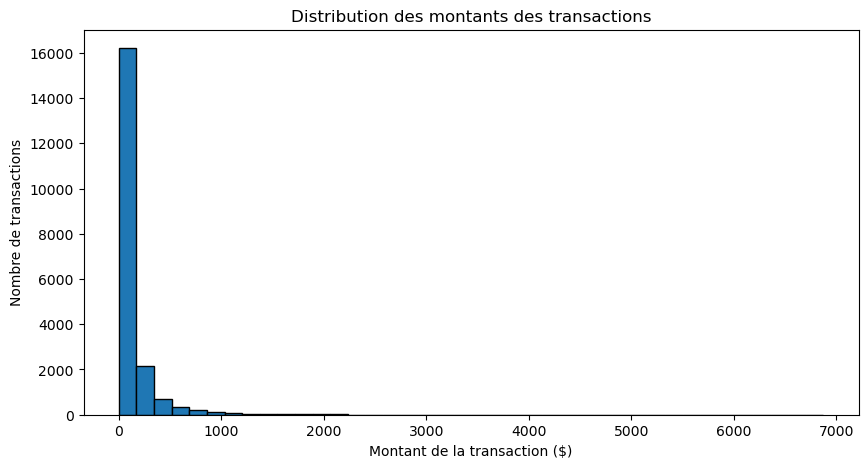

In [7]:

import matplotlib.pyplot as plt

# Créer un histogramme des montants
plt.figure(figsize=(10, 5))

plt.hist(
    df["amount_usd"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution des montants des transactions")
plt.xlabel("Montant de la transaction ($)")
plt.ylabel("Nombre de transactions")

plt.show()


Montants des transactions par catégorie :
            count    mean     std   min    25%    50%     75%      max
is_fraud                                                              
0         19661.0  131.58  254.24  1.00  26.21  57.35  130.88  6872.69
1           339.0  181.25  380.46  4.09  28.62  69.77  165.32  3356.46


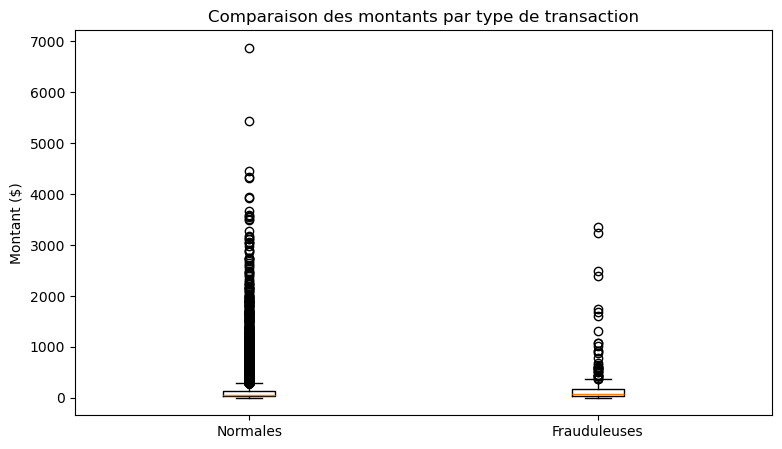

In [8]:

# Séparer les montants selon le type de transaction
montants_normaux = df[df["is_fraud"] == 0]["amount_usd"]
montants_fraudes = df[df["is_fraud"] == 1]["amount_usd"]

# Afficher les statistiques de chaque groupe
print("Montants des transactions par catégorie :")
print(df.groupby("is_fraud")["amount_usd"].describe().round(2))

# Créer le boxplot
plt.figure(figsize=(9, 5))

plt.boxplot(
    [montants_normaux, montants_fraudes],
    tick_labels=["Normales", "Frauduleuses"]
)

plt.title("Comparaison des montants par type de transaction")
plt.ylabel("Montant ($)")

plt.show()


In [9]:

# Analyse des fraudes par catégorie commerciale
analyse_categories = df.groupby("merchant_category")["is_fraud"].agg(
    nombre_transactions="count",
    nombre_fraudes="sum",
    taux_fraude="mean"
)

# Convertir le taux en pourcentage
analyse_categories["taux_fraude"] *= 100

# Trier les catégories par taux de fraude décroissant
analyse_categories = analyse_categories.sort_values(
    by="taux_fraude",
    ascending=False
)

# Afficher les résultats
display(analyse_categories.round(2))


,nombre_transactions,nombre_fraudes,taux_fraude
merchant_category,,,
Crypto Exchange,561,28,4.99
Gift Cards,617,27,4.38
Gaming,1036,38,3.67
Electronics,2032,48,2.36
Streaming,1010,21,2.08
Utilities,1330,25,1.88
Healthcare,1237,16,1.29
Groceries,3242,40,1.23
Fuel,1565,19,1.21


,nombre_transactions,nombre_fraudes,taux_fraude
channel,,,
Online,6810,135,1.98
ATM,1374,25,1.82
In-App,3225,52,1.61
POS,5191,79,1.52
Contactless,3400,48,1.41


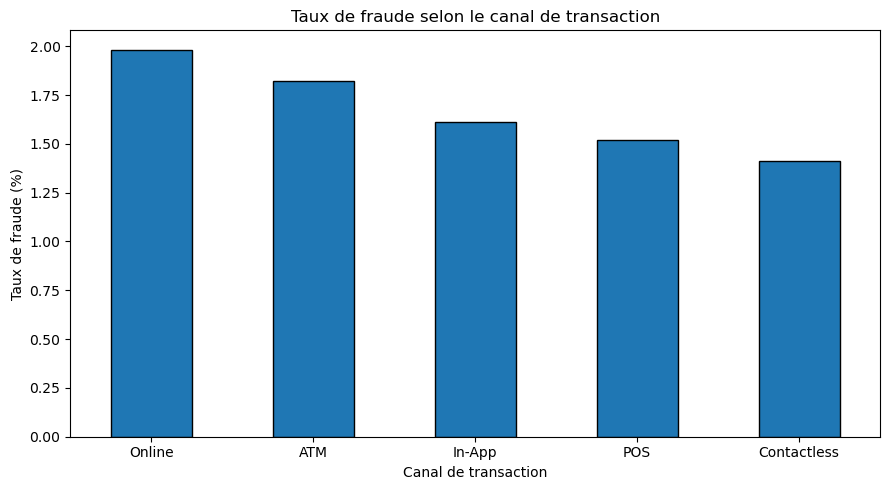

In [10]:

# Analyse des fraudes selon le canal de transaction
analyse_canaux = df.groupby("channel")["is_fraud"].agg(
    nombre_transactions="count",
    nombre_fraudes="sum",
    taux_fraude="mean"
)

# Convertir les proportions en pourcentages
analyse_canaux["taux_fraude"] *= 100

# Classer les canaux par taux de fraude
analyse_canaux = analyse_canaux.sort_values(
    by="taux_fraude",
    ascending=False
)

# Afficher le tableau
display(analyse_canaux.round(2))

# Visualiser les taux de fraude
plt.figure(figsize=(9, 5))

analyse_canaux["taux_fraude"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Taux de fraude selon le canal de transaction")
plt.xlabel("Canal de transaction")
plt.ylabel("Taux de fraude (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


,nombre_transactions,nombre_fraudes,taux_fraude
auth_method,,,
No Authentication,2388,106,4.44
OTP,4792,75,1.57
3D Secure,5554,86,1.55
PIN,4173,48,1.15
Biometric,3093,24,0.78


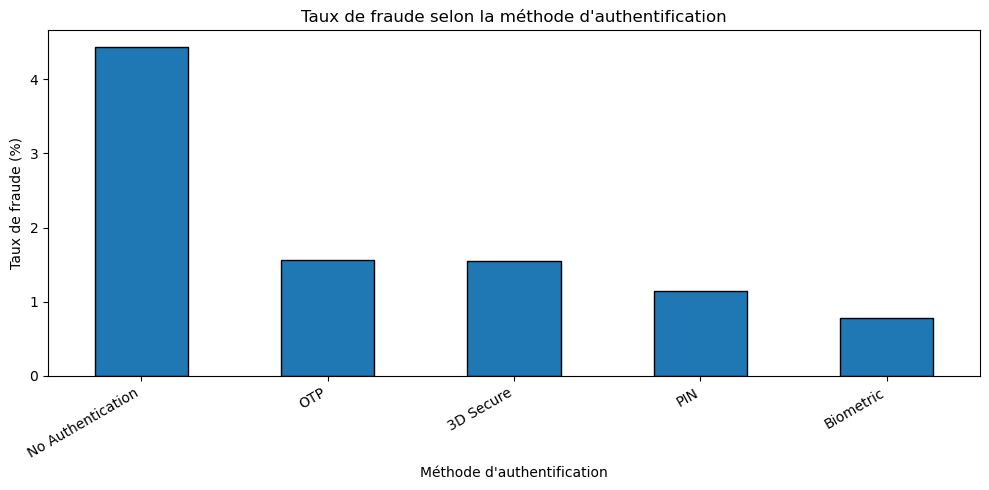

In [11]:

# Analyse des fraudes selon la méthode d'authentification
analyse_auth = df.groupby("auth_method")["is_fraud"].agg(
    nombre_transactions="count",
    nombre_fraudes="sum",
    taux_fraude="mean"
)

# Convertir le taux en pourcentage
analyse_auth["taux_fraude"] *= 100

# Trier les résultats
analyse_auth = analyse_auth.sort_values(
    by="taux_fraude",
    ascending=False
)

# Afficher le tableau
display(analyse_auth.round(2))

# Créer un graphique
plt.figure(figsize=(10, 5))

analyse_auth["taux_fraude"].plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Taux de fraude selon la méthode d'authentification")
plt.xlabel("Méthode d'authentification")
plt.ylabel("Taux de fraude (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()

plt.show()


In [12]:

from sklearn.model_selection import train_test_split

# Séparer les variables explicatives et la variable cible
X = df.drop(columns=["is_fraud", "transaction_id"])
y = df["is_fraud"]

# Répartition 80 % entraînement / 20 % test
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Taille de l'ensemble d'entraînement :", len(X_train))
print("Taille de l'ensemble de test :", len(X_test))

print("\nRépartition des classes dans l'entraînement :")
print(y_train.value_counts())

print("\nRépartition des classes dans le test :")
print(y_test.value_counts())


Taille de l'ensemble d'entraînement : 16000
Taille de l'ensemble de test : 4000

Répartition des classes dans l'entraînement :
is_fraud
0    15729
1      271
Name: count, dtype: int64

Répartition des classes dans le test :
is_fraud
0    3932
1      68
Name: count, dtype: int64


In [13]:

from sklearn.utils import resample
import pandas as pd

# Reconstituer temporairement un tableau
train_df = X_train.copy()
train_df["is_fraud"] = y_train

# Séparer les deux classes
normales = train_df[train_df["is_fraud"] == 0]
fraudes = train_df[train_df["is_fraud"] == 1]

# Suréchantillonner uniquement les fraudes
fraudes_equilibrees = resample(
    fraudes,
    replace=True,
    n_samples=len(normales),
    random_state=42
)

# Réunir les deux classes
train_equilibre = pd.concat(
    [normales, fraudes_equilibrees],
    ignore_index=True
)

# Mélanger les observations
train_equilibre = train_equilibre.sample(
    frac=1,
    random_state=42
).reset_index(drop=True)

# Afficher la nouvelle répartition
print("Avant rééquilibrage :")
print(y_train.value_counts())

print("\nAprès rééquilibrage :")
print(train_equilibre["is_fraud"].value_counts())


Avant rééquilibrage :
is_fraud
0    15729
1      271
Name: count, dtype: int64

Après rééquilibrage :
is_fraud
0    15729
1    15729
Name: count, dtype: int64


In [14]:

# Vérifier les proportions avant et après rééquilibrage
print("AVANT RÉÉQUILIBRAGE")
print(y_train.value_counts(normalize=True).mul(100).round(2))

print("\nAPRÈS RÉÉQUILIBRAGE")
print(
    train_equilibre["is_fraud"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

# Préparer les données de test sans les rééquilibrer
test_df = X_test.copy()
test_df["is_fraud"] = y_test

# Enregistrer les deux ensembles séparément
train_equilibre.to_csv(
    "train_equilibre.csv",
    index=False
)

test_df.to_csv(
    "test_original.csv",
    index=False
)

print("\nFichiers créés avec succès !")


AVANT RÉÉQUILIBRAGE
is_fraud
0    98.31
1     1.69
Name: proportion, dtype: float64

APRÈS RÉÉQUILIBRAGE
is_fraud
0    50.0
1    50.0
Name: proportion, dtype: float64

Fichiers créés avec succès !


In [15]:

# Charger les deux fichiers créés
train_verification = pd.read_csv("train_equilibre.csv")
test_verification = pd.read_csv("test_original.csv")

# Vérifier leurs dimensions
print("Dimensions entraînement :", train_verification.shape)
print("Dimensions test :", test_verification.shape)

# Vérifier la répartition des classes
print("\nEntraînement rééquilibré :")
print(train_verification["is_fraud"].value_counts())

print("\nTest original :")
print(test_verification["is_fraud"].value_counts())

# Vérifier les valeurs manquantes
print("\nValeurs manquantes dans l'entraînement :")
print(train_verification.isnull().sum().sum())

print("\nValeurs manquantes dans le test :")
print(test_verification.isnull().sum().sum())


Dimensions entraînement : (31458, 25)
Dimensions test : (4000, 25)

Entraînement rééquilibré :
is_fraud
0    15729
1    15729
Name: count, dtype: int64

Test original :
is_fraud
0    3932
1      68
Name: count, dtype: int64

Valeurs manquantes dans l'entraînement :
0

Valeurs manquantes dans le test :
0


### Préparation et rééquilibrage des données

Le jeu de données initial contient 20 000 transactions bancaires, dont 19 661 transactions normales et 339 transactions frauduleuses.

Les contrôles effectués n'ont révélé aucun doublon, aucun identifiant de transaction répété, ni aucun montant nul ou négatif. La vérification des valeurs manquantes n'a pas non plus identifié de problème.

Les données ont ensuite été divisées en deux ensembles à l'aide d'une séparation stratifiée :

- **80 % pour l'entraînement**, soit 16 000 transactions.
- **20 % pour le test**, soit 4 000 transactions.

Pour traiter le déséquilibre des classes, un suréchantillonnage aléatoire avec remise a été appliqué exclusivement à l'ensemble d'entraînement.

Après cette opération, l'ensemble d'entraînement contient 31 458 observations : 15 729 transactions normales et 15 729 observations frauduleuses, certaines étant des répétitions de transactions existantes.

L'ensemble de test est resté inchangé, avec 3 932 transactions normales et 68 transactions frauduleuses.

Cette préparation permet d'expérimenter un apprentissage sur des classes équilibrées tout en conservant un ensemble de test représentatif de la distribution initiale. Le suréchantillonnage présente néanmoins un risque de surapprentissage, qui devra être évalué lors de la modélisation.S

In [16]:

# Vérification des valeurs potentiellement incohérentes
print("Âges négatifs :", (df["customer_age"] < 0).sum())

print("Heures invalides :", (
    (df["time_of_day_hour"] < 0) |
    (df["time_of_day_hour"] > 23)
).sum())

print("Distances négatives :", (
    df["distance_from_home_km"] < 0
).sum())

print("Âges de carte négatifs :", (
    df["card_age_months"] < 0
).sum())

print("Valeurs de la cible :", sorted(df["is_fraud"].unique()))

# Examiner les plages des variables
display(
    df[[
        "customer_age",
        "time_of_day_hour",
        "distance_from_home_km",
        "card_age_months"
    ]].agg(["min", "max"])
)


Âges négatifs : 0
Heures invalides : 0
Distances négatives : 0
Âges de carte négatifs : 0
Valeurs de la cible : [np.int64(0), np.int64(1)]


,customer_age,time_of_day_hour,distance_from_home_km,card_age_months
min,18,0,0.00,22
max,81,23,216.19,74


In [17]:

# Identifier les variables numériques et catégorielles
variables_numeriques = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

variables_categorielles = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Identifier également les variables booléennes
variables_booleennes = X_train.select_dtypes(
    include=["bool"]
).columns.tolist()

print("VARIABLES NUMÉRIQUES :")
print(variables_numeriques)

print("\nVARIABLES CATÉGORIELLES :")
print(variables_categorielles)

print("\nVARIABLES BOOLÉENNES :")
print(variables_booleennes)

print("\nNombre total de variables :",
      len(variables_numeriques)
      + len(variables_categorielles)
      + len(variables_booleennes))


VARIABLES NUMÉRIQUES :
['amount_usd', 'hours_since_last_txn', 'txn_count_last_24h', 'distance_from_home_km', 'card_age_months', 'customer_age', 'account_balance_usd', 'cvv_retry_count', 'velocity_score', 'time_of_day_hour', 'day_of_week', 'merchant_risk_score', 'prior_disputes']

VARIABLES CATÉGORIELLES :
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

VARIABLES BOOLÉENNES :
['is_foreign_transaction', 'is_new_merchant', 'used_vpn', 'ip_country_mismatch', 'billing_shipping_mismatch', 'is_ai_generated_scam_attempt']

Nombre total de variables : 24


In [18]:

# Variables à comparer
variables = [
    "merchant_category",
    "channel",
    "auth_method",
    "card_type"
]

# Analyser chaque variable
for variable in variables:
    print(f"\nANALYSE : {variable}")

    resultat = df.groupby(variable)["is_fraud"].agg(
        transactions="count",
        fraudes="sum",
        taux_fraude="mean"
    )

    resultat["taux_fraude"] *= 100

    resultat = resultat.sort_values(
        "taux_fraude",
        ascending=False
    )

    display(resultat.round(2))



ANALYSE : merchant_category


,transactions,fraudes,taux_fraude
merchant_category,,,
Crypto Exchange,561,28,4.99
Gift Cards,617,27,4.38
Gaming,1036,38,3.67
Electronics,2032,48,2.36
Streaming,1010,21,2.08
Utilities,1330,25,1.88
Healthcare,1237,16,1.29
Groceries,3242,40,1.23
Fuel,1565,19,1.21



ANALYSE : channel


,transactions,fraudes,taux_fraude
channel,,,
Online,6810,135,1.98
ATM,1374,25,1.82
In-App,3225,52,1.61
POS,5191,79,1.52
Contactless,3400,48,1.41



ANALYSE : auth_method


,transactions,fraudes,taux_fraude
auth_method,,,
No Authentication,2388,106,4.44
OTP,4792,75,1.57
3D Secure,5554,86,1.55
PIN,4173,48,1.15
Biometric,3093,24,0.78



ANALYSE : card_type


,transactions,fraudes,taux_fraude
card_type,,,
Amex,2135,43,2.01
Discover,1023,20,1.96
Visa,8417,150,1.78
Mastercard,6629,102,1.54
RuPay,1796,24,1.34


In [19]:

# Résumer les résultats des quatre variables étudiées

variables = [
    "merchant_category",
    "channel",
    "auth_method",
    "card_type"
]

for variable in variables:

    analyse = df.groupby(variable)["is_fraud"].agg(
        transactions="count",
        fraudes="sum",
        taux_fraude="mean"
    )

    analyse["taux_fraude"] *= 100

    # Trouver la catégorie avec le taux le plus élevé
    categorie_max = analyse["taux_fraude"].idxmax()
    taux_max = analyse.loc[categorie_max, "taux_fraude"]
    effectif = analyse.loc[categorie_max, "transactions"]

    print(f"\nVariable étudiée : {variable}")
    print(f"Catégorie au taux le plus élevé : {categorie_max}")
    print(f"Taux de fraude : {taux_max:.2f} %")
    print(f"Nombre de transactions : {effectif}")



Variable étudiée : merchant_category
Catégorie au taux le plus élevé : Crypto Exchange
Taux de fraude : 4.99 %
Nombre de transactions : 561

Variable étudiée : channel
Catégorie au taux le plus élevé : Online
Taux de fraude : 1.98 %
Nombre de transactions : 6810

Variable étudiée : auth_method
Catégorie au taux le plus élevé : No Authentication
Taux de fraude : 4.44 %
Nombre de transactions : 2388

Variable étudiée : card_type
Catégorie au taux le plus élevé : Amex
Taux de fraude : 2.01 %
Nombre de transactions : 2135


In [20]:

# Vérification finale des variables

print("Nombre de variables explicatives :", X_train.shape[1])

print("\nVariables catégorielles :")
print(X_train.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist())

print("\nValeurs infinies dans les variables numériques :")
import numpy as np

numeriques = X_train.select_dtypes(include=["number"])

print(np.isinf(numeriques.to_numpy()).sum())

print("\nColonnes contenant une seule valeur distincte :")
colonnes_constantes = [
    col for col in X_train.columns
    if X_train[col].nunique(dropna=False) <= 1
]
print(colonnes_constantes)

print("\nDimensions finales :")
print("Entraînement équilibré :", train_equilibre.shape)
print("Test original :", test_df.shape)


Nombre de variables explicatives : 24

Variables catégorielles :
['merchant_category', 'card_type', 'auth_method', 'channel', 'device_type']

Valeurs infinies dans les variables numériques :
0

Colonnes contenant une seule valeur distincte :
[]

Dimensions finales :
Entraînement équilibré : (31458, 25)
Test original : (4000, 25)
